In [ ]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

In [ ]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

In [ ]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")

In [ ]:
# ============================================================
# CELL 1 — IMPORTS
# ============================================================

import os
import copy
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import datasets
from torchvision import transforms
from torchvision import models

from PIL import Image

import matplotlib.pyplot as plt

from tqdm.auto import tqdm

# HuggingFace Transformer
from transformers import SegformerModel

# Traditional ML
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("All libraries imported successfully.")

In [ ]:
# ============================================================
# CELL 2 — DEVICE, PATHS & REPRODUCIBILITY
# ============================================================

# -----------------------------
# Reproducibility
# -----------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Make CUDA operations as reproducible as practical
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# -----------------------------
# Device
# -----------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# -----------------------------
# Dataset paths
# -----------------------------
TRAIN_DIR = "/kaggle/working/PCOSGen-train/train"
TEST_DIR  = "/kaggle/working/PCOSGen-train/test"


# -----------------------------
# Check paths
# -----------------------------
print("\nDataset paths:")
print("Train:", TRAIN_DIR)
print("Test :", TEST_DIR)

print("\nTrain path exists:", os.path.exists(TRAIN_DIR))
print("Test path exists :", os.path.exists(TEST_DIR))


# -----------------------------
# Basic folder check
# -----------------------------
if os.path.exists(TRAIN_DIR):
    print("\nTrain classes:")
    print(sorted(os.listdir(TRAIN_DIR)))

if os.path.exists(TEST_DIR):
    print("\nTest classes:")
    print(sorted(os.listdir(TEST_DIR)))

In [ ]:
# ============================================================
# CELL 3 — DATASET + 85/15 TRAIN-VALIDATION SPLIT
# ============================================================

from torch.utils.data import Subset

# ------------------------------------------------------------
# Image settings
# ------------------------------------------------------------
IMG_SIZE = 224

# ------------------------------------------------------------
# Training transforms
# Augmentation is applied ONLY to training samples
# ------------------------------------------------------------
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# Validation / Test transforms
# No random augmentation
# ------------------------------------------------------------
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# Load training folder WITHOUT transform
# We need the same indices for train and validation
# ------------------------------------------------------------
full_train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=None
)

# ------------------------------------------------------------
# Load test folder separately
# IMPORTANT: This remains completely untouched until
# final evaluation.
# ------------------------------------------------------------
test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=eval_transform
)


# ------------------------------------------------------------
# Class information
# ------------------------------------------------------------
class_names = full_train_dataset.classes
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)


# ------------------------------------------------------------
# 85 / 15 split
# Stratified split so class proportions are preserved
# ------------------------------------------------------------
from sklearn.model_selection import train_test_split

all_indices = np.arange(len(full_train_dataset))
all_labels = np.array(full_train_dataset.targets)

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.15,
    random_state=SEED,
    stratify=all_labels
)


# ------------------------------------------------------------
# Custom dataset wrapper
# Allows different transforms for train and validation
# ------------------------------------------------------------
class TransformSubset(Dataset):

    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        original_idx = self.indices[idx]

        image, label = self.dataset[original_idx]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# ------------------------------------------------------------
# Create train / validation datasets
# ------------------------------------------------------------
train_dataset = TransformSubset(
    full_train_dataset,
    train_indices,
    transform=train_transform
)

val_dataset = TransformSubset(
    full_train_dataset,
    val_indices,
    transform=eval_transform
)


# ------------------------------------------------------------
# Dataset sizes
# ------------------------------------------------------------
print("\nDataset sizes:")
print("-----------------------------")
print("Total training-folder images :", len(full_train_dataset))
print("Training images              :", len(train_dataset))
print("Validation images            :", len(val_dataset))
print("Test images                  :", len(test_dataset))
print("-----------------------------")


# ------------------------------------------------------------
# Verify no overlap
# ------------------------------------------------------------
train_set = set(train_indices)
val_set = set(val_indices)

overlap = train_set.intersection(val_set)

print("\nTrain/Validation overlap:", len(overlap))

assert len(overlap) == 0, "ERROR: Train and validation overlap detected!"

print("✓ Train/validation split is clean.")
print("✓ Test set is kept separate.")

In [ ]:
# ============================================================
# CELL 4 — DATALOADERS + CLASS DISTRIBUTION
# ============================================================

BATCH_SIZE = 32

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ------------------------------------------------------------
# Class distribution
# ------------------------------------------------------------

train_labels = all_labels[train_indices]
val_labels = all_labels[val_indices]
test_labels = np.array(test_dataset.targets)

print("Class distribution")
print("=" * 50)

for idx, class_name in enumerate(class_names):

    train_count = np.sum(train_labels == idx)
    val_count = np.sum(val_labels == idx)
    test_count = np.sum(test_labels == idx)

    print(f"\nClass: {class_name}")
    print(f"  Train      : {train_count}")
    print(f"  Validation : {val_count}")
    print(f"  Test       : {test_count}")


# ------------------------------------------------------------
# Check one batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))

print("\n" + "=" * 50)
print("Batch verification")
print("=" * 50)

print("Image batch shape :", images.shape)
print("Label batch shape :", labels.shape)
print("Image dtype       :", images.dtype)
print("Label dtype       :", labels.dtype)

print("\nExpected image shape:")
print("(batch_size, 3, 224, 224)")

In [ ]:
# ============================================================
# CELL 5 — VISUALIZE TRAINING SAMPLES
# ============================================================

# ------------------------------------------------------------
# Get one batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))


# ------------------------------------------------------------
# ImageNet normalization values
# Used to convert images back for visualization
# ------------------------------------------------------------

mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)


# ------------------------------------------------------------
# Plot samples
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):

    # Convert CHW -> HWC
    image = images[i].cpu() * std + mean
    image = torch.clamp(image, 0, 1)

    image = image.permute(1, 2, 0).numpy()

    ax.imshow(image)

    ax.set_title(
        class_names[labels[i].item()],
        fontsize=11
    )

    ax.axis("off")


plt.suptitle(
    "PCOS Ultrasound Training Samples",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 6 — MiT-B2 + FPN CLASSIFICATION MODEL
# ============================================================

# ------------------------------------------------------------
# MiT-B2 Feature + FPN Model
# ------------------------------------------------------------

class MiTB2_FPN_Classifier(nn.Module):

    def __init__(self, num_classes=2, fpn_channels=256):

        super().__init__()

        # ----------------------------------------------------
        # MiT-B2 Transformer backbone
        # ----------------------------------------------------
        self.mit = SegformerModel.from_pretrained(
            "nvidia/mit-b2"
        )

        # MiT-B2 encoder output channels
        # Stage 1 = 64
        # Stage 2 = 128
        # Stage 3 = 320
        # Stage 4 = 512
        self.stage_channels = [64, 128, 320, 512]

        # ----------------------------------------------------
        # FPN lateral projections
        # ----------------------------------------------------
        self.lateral_convs = nn.ModuleList([
            nn.Conv2d(
                in_channels=c,
                out_channels=fpn_channels,
                kernel_size=1
            )
            for c in self.stage_channels
        ])

        # ----------------------------------------------------
        # FPN refinement
        # ----------------------------------------------------
        self.fpn_refine = nn.Sequential(
            nn.Conv2d(
                fpn_channels,
                fpn_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(fpn_channels),
            nn.ReLU(inplace=True)
        )

        # ----------------------------------------------------
        # Global feature extraction
        # ----------------------------------------------------
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # ----------------------------------------------------
        # Classification head
        # ----------------------------------------------------
        self.dropout = nn.Dropout(p=0.3)

        self.classifier = nn.Linear(
            fpn_channels,
            num_classes
        )

    # --------------------------------------------------------
    # Convert HuggingFace hidden state to BCHW
    # --------------------------------------------------------
    def _to_bchw(self, x, expected_channels, height, width):

        # Case 1:
        # Already [B, C, H, W]
        if x.dim() == 4:
            return x

        # Case 2:
        # [B, N, C]
        elif x.dim() == 3:

            B, N, C = x.shape

            if C != expected_channels:
                raise RuntimeError(
                    f"Expected {expected_channels} channels, "
                    f"but received {C}."
                )

            if N != height * width:
                raise RuntimeError(
                    f"Cannot reshape {N} tokens into "
                    f"{height} x {width}."
                )

            x = x.transpose(1, 2)

            x = x.reshape(
                B,
                C,
                height,
                width
            )

            return x

        else:

            raise RuntimeError(
                f"Unexpected tensor dimension: {x.dim()}"
            )

    # --------------------------------------------------------
    # Forward
    # --------------------------------------------------------
    def forward(self, x, return_features=False):

        # ----------------------------------------------------
        # MiT-B2 encoder
        # ----------------------------------------------------
        outputs = self.mit(
            pixel_values=x,
            output_hidden_states=True
        )

        hidden_states = outputs.hidden_states

        # Last 4 encoder stages
        stage_features = hidden_states[-4:]

        # ----------------------------------------------------
        # Expected spatial resolutions for 224x224 input
        # ----------------------------------------------------
        resolutions = [
            (56, 56),
            (28, 28),
            (14, 14),
            (7, 7)
        ]

        processed_features = []

        # ----------------------------------------------------
        # Convert every stage to BCHW
        # ----------------------------------------------------
        for feature, channels, (h, w) in zip(
            stage_features,
            self.stage_channels,
            resolutions
        ):

            feature = self._to_bchw(
                feature,
                channels,
                h,
                w
            )

            processed_features.append(feature)

        # ----------------------------------------------------
        # FPN
        #
        # Start from the highest-resolution feature.
        # Upsample all deeper stages to 56x56.
        # ----------------------------------------------------

        target_size = processed_features[0].shape[-2:]

        fpn_output = 0

        for feature, lateral in zip(
            processed_features,
            self.lateral_convs
        ):

            feature = lateral(feature)

            if feature.shape[-2:] != target_size:

                feature = F.interpolate(
                    feature,
                    size=target_size,
                    mode="bilinear",
                    align_corners=False
                )

            fpn_output = fpn_output + feature

        # ----------------------------------------------------
        # FPN refinement
        # ----------------------------------------------------
        fpn_output = self.fpn_refine(fpn_output)

        # ----------------------------------------------------
        # Global feature vector
        # ----------------------------------------------------
        features = self.global_pool(
            fpn_output
        )

        features = torch.flatten(
            features,
            start_dim=1
        )

        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------
        logits = self.classifier(
            self.dropout(features)
        )

        # ----------------------------------------------------
        # Return feature vector when requested
        # ----------------------------------------------------
        if return_features:

            return logits, features

        return logits


# ============================================================
# Create model
# ============================================================

mit_fpn_model = MiTB2_FPN_Classifier(
    num_classes=num_classes,
    fpn_channels=256
)

mit_fpn_model = mit_fpn_model.to(device)


# ============================================================
# Verify model
# ============================================================

print("MiT-B2 + FPN model created successfully.")

print("\nTrainable parameters:")
trainable_params = sum(
    p.numel()
    for p in mit_fpn_model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in mit_fpn_model.parameters()
)

print(f"Trainable parameters : {trainable_params:,}")
print(f"Total parameters     : {total_params:,}")


# ============================================================
# Test forward pass
# ============================================================

with torch.no_grad():

    sample_images, sample_labels = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(device)

    sample_logits, sample_features = mit_fpn_model(
        sample_images,
        return_features=True
    )

print("\nForward-pass verification:")
print("Input shape     :", sample_images.shape)
print("Feature shape   :", sample_features.shape)
print("Logit shape     :", sample_logits.shape)

print("\nExpected:")
print("Feature shape   : [batch_size, 256]")
print("Logit shape     : [batch_size, 2]")

In [ ]:
# ============================================================
# CELL 7 — MiT-B2 + FPN TRAINING SETUP
# ============================================================

# ------------------------------------------------------------
# Loss function
# ------------------------------------------------------------
criterion_mit = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# Optimizer
#
# Smaller LR for pretrained MiT-B2
# Larger LR for newly initialized FPN + classifier
# ------------------------------------------------------------

mit_backbone_params = []
new_params = []

for name, param in mit_fpn_model.named_parameters():

    if not param.requires_grad:
        continue

    if name.startswith("mit."):
        mit_backbone_params.append(param)
    else:
        new_params.append(param)


optimizer_mit = torch.optim.AdamW(
    [
        {
            "params": mit_backbone_params,
            "lr": 1e-5
        },
        {
            "params": new_params,
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)


# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler_mit = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mit,
    mode="min",
    factor=0.5,
    patience=2
)


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

NUM_EPOCHS_MIT = 15

best_val_loss_mit = float("inf")
best_val_acc_mit = 0.0

best_mit_state = None

patience_mit = 4
epochs_without_improvement = 0


# ------------------------------------------------------------
# History
# ------------------------------------------------------------

mit_train_losses = []
mit_val_losses = []

mit_train_accs = []
mit_val_accs = []


# ------------------------------------------------------------
# Print setup
# ------------------------------------------------------------

print("MiT-B2 + FPN training setup complete.")
print()
print("Loss function       : CrossEntropyLoss")
print("Optimizer           : AdamW")
print("MiT-B2 learning rate: 1e-5")
print("FPN/head LR         : 1e-4")
print("Weight decay        : 1e-4")
print("Max epochs          :", NUM_EPOCHS_MIT)
print("Early stopping      : patience =", patience_mit)

print("\nTrainable parameter groups:")
print("MiT-B2 parameters   :", sum(p.numel() for p in mit_backbone_params))
print("FPN + classifier    :", sum(p.numel() for p in new_params))

In [34]:
# ============================================================
# CELL 8 — TRAIN MiT-B2 + FPN FOR UP TO 30 EPOCHS
# ============================================================

import copy
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

NUM_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 6

criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer_mit = torch.optim.AdamW(
    [
        {
            "params": model_mit.mit.parameters(),
            "lr": 1e-5
        },
        {
            "params": model_mit.lateral_convs.parameters(),
            "lr": 1e-4
        },
        {
            "params": model_mit.fpn_refine.parameters(),
            "lr": 1e-4
        },
        {
            "params": model_mit.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

scheduler_mit = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mit,
    mode="min",
    factor=0.5,
    patience=2
)

best_val_loss = float("inf")
best_mit_state = copy.deepcopy(model_mit.state_dict())
early_stop_counter = 0

mit_train_losses = []
mit_val_losses = []
mit_train_accs = []
mit_val_accs = []

print("=" * 65)
print("TRAINING MiT-B2 + FPN")
print("=" * 65)

start_time = time.time()

for epoch in range(NUM_EPOCHS):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------
    model_mit.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_mit.zero_grad()

        outputs = model_mit(images)
        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_mit.parameters(),
            max_norm=1.0
        )

        optimizer_mit.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------
    model_mit.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_mit(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    # Scheduler
    scheduler_mit.step(val_loss)

    # Store history
    mit_train_losses.append(train_loss)
    mit_val_losses.append(val_loss)
    mit_train_accs.append(train_acc)
    mit_val_accs.append(val_acc)

    current_lr = optimizer_mit.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.2e}"
    )

    # --------------------------------------------------------
    # BEST MODEL + EARLY STOPPING
    # --------------------------------------------------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_mit_state = copy.deepcopy(model_mit.state_dict())

        early_stop_counter = 0

        print("  ✓ Best MiT model saved")

    else:

        early_stop_counter += 1

        print(
            f"  No improvement "
            f"({early_stop_counter}/{EARLY_STOPPING_PATIENCE})"
        )

        if early_stop_counter >= EARLY_STOPPING_PATIENCE:

            print("\nEarly stopping triggered.")
            break

elapsed = time.time() - start_time

# Restore best validation model
model_mit.load_state_dict(best_mit_state)

print("\n" + "=" * 65)
print("MiT-B2 TRAINING COMPLETE")
print("=" * 65)
print(f"Best Validation Loss : {best_val_loss:.4f}")
print(f"Best Epoch           : {np.argmin(mit_val_losses) + 1}")
print(f"Epochs Completed     : {len(mit_train_losses)}")
print(f"Training Time        : {elapsed / 60:.2f} minutes")
print("=" * 65)

TRAINING MiT-B2 + FPN
Epoch [01/30] | Train Loss: 0.4226 | Train Acc: 0.7824 | Val Loss: 0.5077 | Val Acc: 0.7667 | LR: 1.00e-05
  ✓ Best MiT model saved
Epoch [02/30] | Train Loss: 0.4193 | Train Acc: 0.7824 | Val Loss: 0.4963 | Val Acc: 0.7688 | LR: 1.00e-05
  ✓ Best MiT model saved
Epoch [03/30] | Train Loss: 0.4210 | Train Acc: 0.7901 | Val Loss: 0.4857 | Val Acc: 0.7708 | LR: 1.00e-05
  ✓ Best MiT model saved
Epoch [04/30] | Train Loss: 0.4054 | Train Acc: 0.7915 | Val Loss: 0.5106 | Val Acc: 0.7646 | LR: 1.00e-05
  No improvement (1/6)
Epoch [05/30] | Train Loss: 0.4016 | Train Acc: 0.7919 | Val Loss: 0.5143 | Val Acc: 0.7688 | LR: 1.00e-05
  No improvement (2/6)
Epoch [06/30] | Train Loss: 0.4072 | Train Acc: 0.7919 | Val Loss: 0.4986 | Val Acc: 0.7688 | LR: 5.00e-06
  No improvement (3/6)
Epoch [07/30] | Train Loss: 0.3866 | Train Acc: 0.7985 | Val Loss: 0.5236 | Val Acc: 0.7688 | LR: 5.00e-06
  No improvement (4/6)
Epoch [08/30] | Train Loss: 0.3911 | Train Acc: 0.7956 | Val L

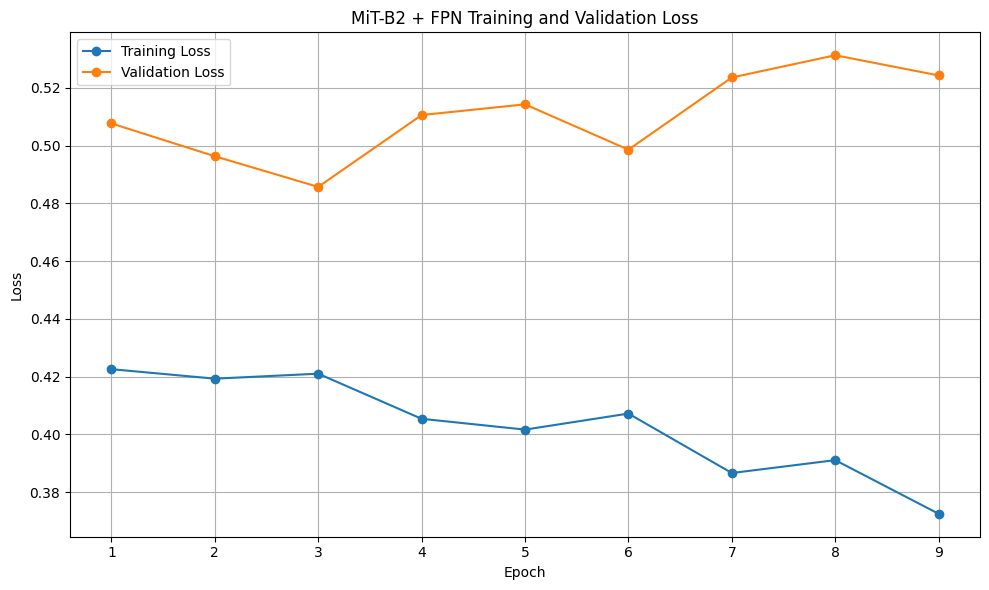

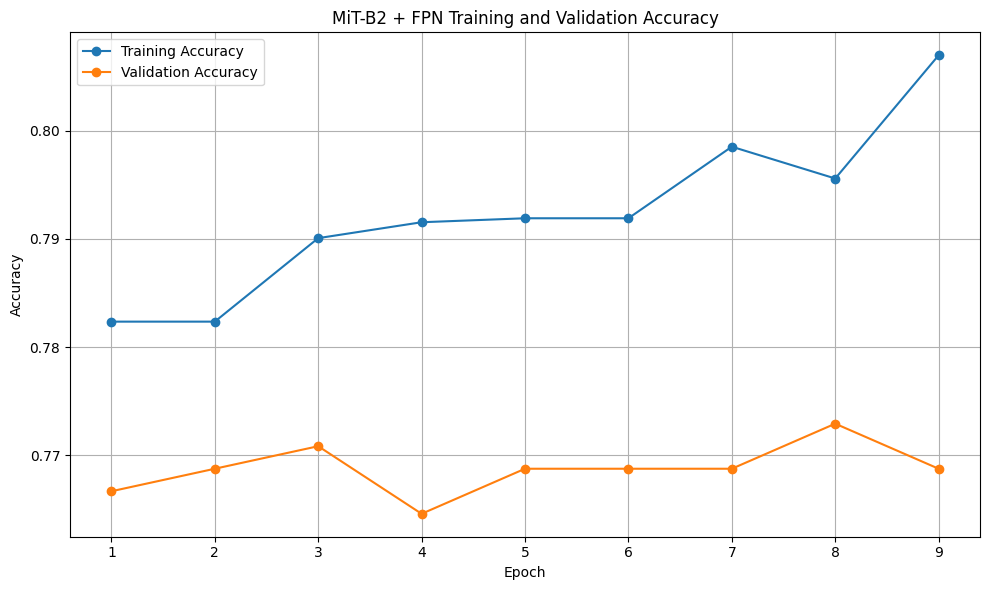

MiT-B2 + FPN TRAINING SUMMARY
Best Epoch          : 3
Best Validation Loss: 0.4857
Validation Accuracy : 0.7708


In [35]:
# ============================================================
# CELL 9 — MiT-B2 + FPN TRAINING GRAPHS
# ============================================================

epochs_completed = range(
    1,
    len(mit_train_losses) + 1
)

# ------------------------------------------------------------
# 1. Loss Curve
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_completed,
    mit_train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_completed,
    mit_val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MiT-B2 + FPN Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Accuracy Curve
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_completed,
    mit_train_accs,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_completed,
    mit_val_accs,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MiT-B2 + FPN Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Print best validation results
# ------------------------------------------------------------

best_epoch = np.argmin(mit_val_losses) + 1

print("=" * 60)
print("MiT-B2 + FPN TRAINING SUMMARY")
print("=" * 60)

print(f"Best Epoch          : {best_epoch}")
print(f"Best Validation Loss: {min(mit_val_losses):.4f}")
print(
    f"Validation Accuracy : "
    f"{mit_val_accs[best_epoch - 1]:.4f}"
)

print("=" * 60)

In [36]:
# ============================================================
# CELL 10 — MobileNetV2 CLASSIFICATION MODEL
# ============================================================

# ------------------------------------------------------------
# Load pretrained MobileNetV2
# ------------------------------------------------------------

mobilenet_model = models.mobilenet_v2(
    weights=models.MobileNet_V2_Weights.DEFAULT
)


# ------------------------------------------------------------
# Replace classifier
# ------------------------------------------------------------

in_features = mobilenet_model.classifier[1].in_features

mobilenet_model.classifier[1] = nn.Linear(
    in_features,
    num_classes
)


# ------------------------------------------------------------
# Keep MobileNetV2 FULLY TRAINABLE
# ------------------------------------------------------------

for param in mobilenet_model.parameters():
    param.requires_grad = True


# ------------------------------------------------------------
# Move to GPU / CPU
# ------------------------------------------------------------

mobilenet_model = mobilenet_model.to(device)


# ------------------------------------------------------------
# Verify architecture
# ------------------------------------------------------------

print("MobileNetV2 created successfully.")

print("\nOriginal feature dimension:")
print("1280")

print("\nClassifier:")
print(mobilenet_model.classifier)

# ------------------------------------------------------------
# Parameter counts
# ------------------------------------------------------------

trainable_params_mobilenet = sum(
    p.numel()
    for p in mobilenet_model.parameters()
    if p.requires_grad
)

total_params_mobilenet = sum(
    p.numel()
    for p in mobilenet_model.parameters()
)

print("\nParameter summary:")
print(
    f"Trainable parameters : "
    f"{trainable_params_mobilenet:,}"
)

print(
    f"Total parameters     : "
    f"{total_params_mobilenet:,}"
)


# ------------------------------------------------------------
# Test forward pass
# ------------------------------------------------------------

with torch.no_grad():

    sample_images, sample_labels = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(device)

    sample_logits = mobilenet_model(
        sample_images
    )

print("\nForward-pass verification:")
print("Input shape :", sample_images.shape)
print("Output shape:", sample_logits.shape)

print("\nExpected output:")
print(f"[batch_size, {num_classes}]")

MobileNetV2 created successfully.

Original feature dimension:
1280

Classifier:
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)

Parameter summary:
Trainable parameters : 2,226,434
Total parameters     : 2,226,434

Forward-pass verification:
Input shape : torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 2])

Expected output:
[batch_size, 2]


In [37]:
# ============================================================
# CELL 11 — MobileNetV2 TRAINING SETUP
# ============================================================

# ------------------------------------------------------------
# Loss function
# ------------------------------------------------------------

criterion_mobilenet = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# Separate backbone and classifier parameters
# ------------------------------------------------------------

mobilenet_backbone_params = []
mobilenet_head_params = []

for name, param in mobilenet_model.named_parameters():

    if not param.requires_grad:
        continue

    if name.startswith("classifier."):
        mobilenet_head_params.append(param)
    else:
        mobilenet_backbone_params.append(param)


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_mobilenet = torch.optim.AdamW(
    [
        {
            "params": mobilenet_backbone_params,
            "lr": 1e-5
        },
        {
            "params": mobilenet_head_params,
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)


# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------

scheduler_mobilenet = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mobilenet,
    mode="min",
    factor=0.5,
    patience=2
)


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

NUM_EPOCHS_MOBILENET = 15

best_val_loss_mobilenet = float("inf")
best_val_acc_mobilenet = 0.0

best_mobilenet_state = None

patience_mobilenet = 4
epochs_without_improvement_mobilenet = 0


# ------------------------------------------------------------
# Training history
# ------------------------------------------------------------

mobilenet_train_losses = []
mobilenet_val_losses = []

mobilenet_train_accs = []
mobilenet_val_accs = []


# ------------------------------------------------------------
# Print configuration
# ------------------------------------------------------------

print("MobileNetV2 training setup complete.")
print()
print("Loss function          : CrossEntropyLoss")
print("Optimizer              : AdamW")
print("Backbone learning rate : 1e-5")
print("Classifier learning rate: 1e-4")
print("Weight decay           : 1e-4")
print("Maximum epochs        :", NUM_EPOCHS_MOBILENET)
print("Early stopping        : patience =", patience_mobilenet)

print("\nTrainable parameter groups:")
print(
    "MobileNetV2 backbone :",
    sum(p.numel() for p in mobilenet_backbone_params)
)

print(
    "Classifier head      :",
    sum(p.numel() for p in mobilenet_head_params)
)

MobileNetV2 training setup complete.

Loss function          : CrossEntropyLoss
Optimizer              : AdamW
Backbone learning rate : 1e-5
Classifier learning rate: 1e-4
Weight decay           : 1e-4
Maximum epochs        : 15
Early stopping        : patience = 4

Trainable parameter groups:
MobileNetV2 backbone : 2223872
Classifier head      : 2562


In [38]:
# ============================================================
# CELL 12 — TRAIN MobileNetV2 FOR UP TO 30 EPOCHS
# ============================================================

import copy
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

NUM_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 6

criterion_mobilenet = nn.CrossEntropyLoss()

# Optimizer
optimizer_mobilenet = torch.optim.AdamW(
    [
        {
            "params": mobilenet_model.features.parameters(),
            "lr": 1e-5
        },
        {
            "params": mobilenet_model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

scheduler_mobilenet = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mobilenet,
    mode="min",
    factor=0.5,
    patience=2
)

best_val_loss_mobilenet = float("inf")
best_mobilenet_state = copy.deepcopy(
    mobilenet_model.state_dict()
)

early_stop_counter = 0

mobilenet_train_losses = []
mobilenet_val_losses = []
mobilenet_train_accs = []
mobilenet_val_accs = []

print("=" * 65)
print("TRAINING MobileNetV2")
print("=" * 65)

start_time = time.time()

for epoch in range(NUM_EPOCHS):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------
    mobilenet_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_mobilenet.zero_grad()

        outputs = mobilenet_model(images)
        loss = criterion_mobilenet(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            mobilenet_model.parameters(),
            max_norm=1.0
        )

        optimizer_mobilenet.step()

        train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------
    mobilenet_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = mobilenet_model(images)
            loss = criterion_mobilenet(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    # Scheduler
    scheduler_mobilenet.step(val_loss)

    # Store history
    mobilenet_train_losses.append(train_loss)
    mobilenet_val_losses.append(val_loss)
    mobilenet_train_accs.append(train_acc)
    mobilenet_val_accs.append(val_acc)

    current_lr = optimizer_mobilenet.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.2e}"
    )

    # --------------------------------------------------------
    # BEST MODEL + EARLY STOPPING
    # --------------------------------------------------------
    if val_loss < best_val_loss_mobilenet:

        best_val_loss_mobilenet = val_loss
        best_mobilenet_state = copy.deepcopy(
            mobilenet_model.state_dict()
        )

        early_stop_counter = 0

        print("  ✓ Best MobileNetV2 model saved")

    else:

        early_stop_counter += 1

        print(
            f"  No improvement "
            f"({early_stop_counter}/{EARLY_STOPPING_PATIENCE})"
        )

        if early_stop_counter >= EARLY_STOPPING_PATIENCE:

            print("\nEarly stopping triggered.")
            break

elapsed = time.time() - start_time

# Restore best validation model
mobilenet_model.load_state_dict(best_mobilenet_state)

print("\n" + "=" * 65)
print("MobileNetV2 TRAINING COMPLETE")
print("=" * 65)
print(f"Best Validation Loss : {best_val_loss_mobilenet:.4f}")
print(
    f"Best Epoch           : "
    f"{np.argmin(mobilenet_val_losses) + 1}"
)
print(f"Epochs Completed     : {len(mobilenet_train_losses)}")
print(f"Training Time        : {elapsed / 60:.2f} minutes")
print("=" * 65)

TRAINING MobileNetV2
Epoch [01/30] | Train Loss: 0.5870 | Train Acc: 0.7114 | Val Loss: 0.5543 | Val Acc: 0.7208 | LR: 1.00e-05
  ✓ Best MobileNetV2 model saved
Epoch [02/30] | Train Loss: 0.5314 | Train Acc: 0.7375 | Val Loss: 0.5221 | Val Acc: 0.7479 | LR: 1.00e-05
  ✓ Best MobileNetV2 model saved
Epoch [03/30] | Train Loss: 0.4960 | Train Acc: 0.7603 | Val Loss: 0.5036 | Val Acc: 0.7500 | LR: 1.00e-05
  ✓ Best MobileNetV2 model saved
Epoch [04/30] | Train Loss: 0.4821 | Train Acc: 0.7603 | Val Loss: 0.4953 | Val Acc: 0.7458 | LR: 1.00e-05
  ✓ Best MobileNetV2 model saved
Epoch [05/30] | Train Loss: 0.4672 | Train Acc: 0.7618 | Val Loss: 0.4897 | Val Acc: 0.7479 | LR: 1.00e-05
  ✓ Best MobileNetV2 model saved
Epoch [06/30] | Train Loss: 0.4581 | Train Acc: 0.7654 | Val Loss: 0.4856 | Val Acc: 0.7542 | LR: 1.00e-05
  ✓ Best MobileNetV2 model saved
Epoch [07/30] | Train Loss: 0.4438 | Train Acc: 0.7710 | Val Loss: 0.4832 | Val Acc: 0.7562 | LR: 1.00e-05
  ✓ Best MobileNetV2 model saved

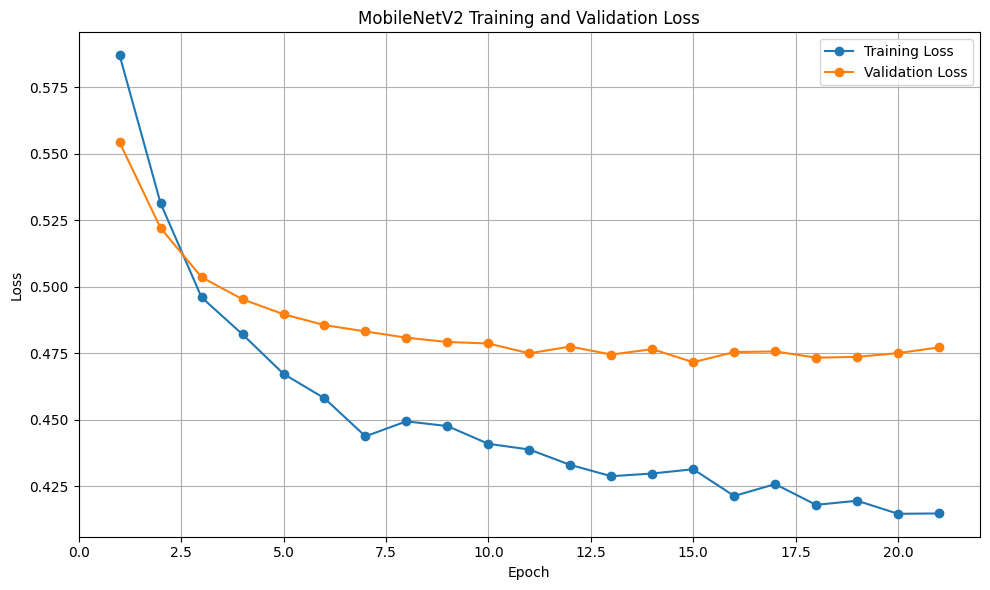

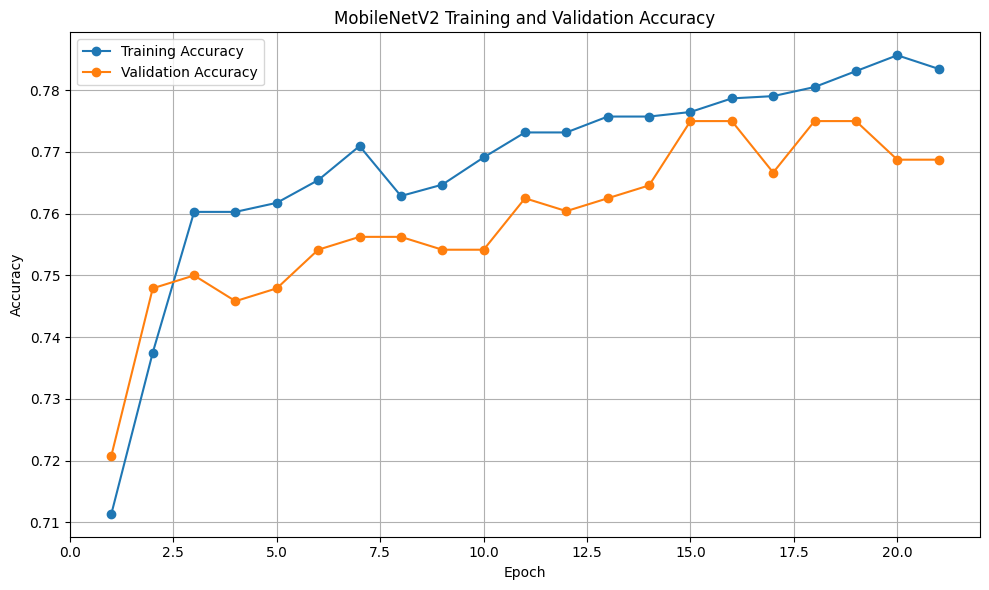

MobileNetV2 TRAINING SUMMARY
Best Epoch           : 15
Best Validation Loss : 0.4716
Validation Accuracy  : 0.7750


In [39]:
# ============================================================
# CELL 13 — MobileNetV2 TRAINING GRAPHS
# ============================================================

epochs_completed_mobilenet = range(
    1,
    len(mobilenet_train_losses) + 1
)


# ============================================================
# 1. LOSS CURVE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_completed_mobilenet,
    mobilenet_train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_completed_mobilenet,
    mobilenet_val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "MobileNetV2 Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 2. ACCURACY CURVE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_completed_mobilenet,
    mobilenet_train_accs,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_completed_mobilenet,
    mobilenet_val_accs,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "MobileNetV2 Training and Validation Accuracy"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 3. BEST VALIDATION RESULT
# ============================================================

best_epoch_mobilenet = (
    np.argmin(mobilenet_val_losses) + 1
)

print("=" * 60)
print("MobileNetV2 TRAINING SUMMARY")
print("=" * 60)

print(
    f"Best Epoch           : "
    f"{best_epoch_mobilenet}"
)

print(
    f"Best Validation Loss : "
    f"{min(mobilenet_val_losses):.4f}"
)

print(
    f"Validation Accuracy  : "
    f"{mobilenet_val_accs[best_epoch_mobilenet - 1]:.4f}"
)

print("=" * 60)

In [40]:
# ============================================================
# CELL 14 — EXTRACT MiT-B2 + FPN FEATURES
# ============================================================

# ------------------------------------------------------------
# Make sure the best MiT-B2 model is loaded
# ------------------------------------------------------------

mit_fpn_model.load_state_dict(
    best_mit_state
)

mit_fpn_model.eval()


# ------------------------------------------------------------
# Feature extraction function
# ------------------------------------------------------------

def extract_mit_features(model, loader, device):

    all_features = []
    all_labels = []

    with torch.no_grad():

        feature_bar = tqdm(
            loader,
            desc="Extracting MiT-B2 + FPN features"
        )

        for images, labels in feature_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            # return_features=True gives:
            # logits, 256-dimensional features
            _, features = model(
                images,
                return_features=True
            )

            all_features.append(
                features.cpu().numpy()
            )

            all_labels.append(
                labels.numpy()
            )

    all_features = np.concatenate(
        all_features,
        axis=0
    )

    all_labels = np.concatenate(
        all_labels,
        axis=0
    )

    return all_features, all_labels


# ============================================================
# Extract TRAIN features
# ============================================================

mit_train_features, mit_train_labels = extract_mit_features(
    mit_fpn_model,
    train_loader,
    device
)


# ============================================================
# Extract VALIDATION features
# ============================================================

mit_val_features, mit_val_labels = extract_mit_features(
    mit_fpn_model,
    val_loader,
    device
)


# ============================================================
# Basic verification
# ============================================================

print("\n" + "=" * 60)
print("MiT-B2 + FPN FEATURE EXTRACTION")
print("=" * 60)

print(
    "Train feature shape:",
    mit_train_features.shape
)

print(
    "Train label shape  :",
    mit_train_labels.shape
)

print(
    "Validation feature shape:",
    mit_val_features.shape
)

print(
    "Validation label shape  :",
    mit_val_labels.shape
)

print("=" * 60)

print("\nExpected:")
print("Train      : (2720, 256)")
print("Validation : (480, 256)")

Extracting MiT-B2 + FPN features:   0%|          | 0/85 [00:00<?, ?it/s]

Extracting MiT-B2 + FPN features:   0%|          | 0/15 [00:00<?, ?it/s]


MiT-B2 + FPN FEATURE EXTRACTION
Train feature shape: (2720, 256)
Train label shape  : (2720,)
Validation feature shape: (480, 256)
Validation label shape  : (480,)

Expected:
Train      : (2720, 256)
Validation : (480, 256)


In [41]:
# ============================================================
# CELL 15 — EXTRACT MobileNetV2 FEATURES
# ============================================================

# ------------------------------------------------------------
# Make sure the BEST fine-tuned MobileNetV2 is loaded
# ------------------------------------------------------------

mobilenet_model.load_state_dict(
    best_mobilenet_state
)

mobilenet_model.eval()


# ------------------------------------------------------------
# Feature extraction function
# ------------------------------------------------------------

def extract_mobilenet_features(model, loader, device):

    all_features = []
    all_labels = []

    with torch.no_grad():

        feature_bar = tqdm(
            loader,
            desc="Extracting MobileNetV2 features"
        )

        for images, labels in feature_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            # ------------------------------------------------
            # MobileNetV2 feature extractor
            #
            # features:
            # [B, 1280, H, W]
            # ------------------------------------------------

            features = model.features(images)

            # ------------------------------------------------
            # Global Average Pooling
            # ------------------------------------------------

            features = F.adaptive_avg_pool2d(
                features,
                (1, 1)
            )

            # ------------------------------------------------
            # Flatten
            # [B, 1280, 1, 1]
            # →
            # [B, 1280]
            # ------------------------------------------------

            features = torch.flatten(
                features,
                start_dim=1
            )

            all_features.append(
                features.cpu().numpy()
            )

            all_labels.append(
                labels.numpy()
            )

    all_features = np.concatenate(
        all_features,
        axis=0
    )

    all_labels = np.concatenate(
        all_labels,
        axis=0
    )

    return all_features, all_labels


# ============================================================
# Extract TRAIN features
# ============================================================

mobilenet_train_features, mobilenet_train_labels = (
    extract_mobilenet_features(
        mobilenet_model,
        train_loader,
        device
    )
)


# ============================================================
# Extract VALIDATION features
# ============================================================

mobilenet_val_features, mobilenet_val_labels = (
    extract_mobilenet_features(
        mobilenet_model,
        val_loader,
        device
    )
)


# ============================================================
# Verification
# ============================================================

print("\n" + "=" * 60)
print("MobileNetV2 FEATURE EXTRACTION")
print("=" * 60)

print(
    "Train feature shape:",
    mobilenet_train_features.shape
)

print(
    "Train label shape  :",
    mobilenet_train_labels.shape
)

print(
    "Validation feature shape:",
    mobilenet_val_features.shape
)

print(
    "Validation label shape  :",
    mobilenet_val_labels.shape
)

print("=" * 60)

print("\nExpected:")
print("Train      : (2720, 1280)")
print("Validation : (480, 1280)")

Extracting MobileNetV2 features:   0%|          | 0/85 [00:00<?, ?it/s]

Extracting MobileNetV2 features:   0%|          | 0/15 [00:00<?, ?it/s]


MobileNetV2 FEATURE EXTRACTION
Train feature shape: (2720, 1280)
Train label shape  : (2720,)
Validation feature shape: (480, 1280)
Validation label shape  : (480,)

Expected:
Train      : (2720, 1280)
Validation : (480, 1280)


In [42]:
# ============================================================
# CELL 16 — CREATE DETERMINISTIC FEATURE LOADERS
# ============================================================

# IMPORTANT:
# train_loader uses shuffle=True for neural-network training.
# For feature fusion, both models MUST see samples in exactly
# the same order.
#
# Therefore we create separate loaders with shuffle=False.

feature_train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

feature_val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Deterministic feature loaders created.")

print("\nTraining loader:")
print("  Shuffle: False")

print("\nValidation loader:")
print("  Shuffle: False")

Deterministic feature loaders created.

Training loader:
  Shuffle: False

Validation loader:
  Shuffle: False


In [43]:
# ============================================================
# CELL 17 — RE-EXTRACT FEATURES WITH IDENTICAL SAMPLE ORDER
# ============================================================

# ============================================================
# 1. MiT-B2 + FPN FEATURES
# ============================================================

mit_fpn_model.load_state_dict(best_mit_state)
mit_fpn_model.eval()

mit_train_features, mit_train_labels = extract_mit_features(
    mit_fpn_model,
    feature_train_loader,
    device
)

mit_val_features, mit_val_labels = extract_mit_features(
    mit_fpn_model,
    feature_val_loader,
    device
)


# ============================================================
# 2. MobileNetV2 FEATURES
# ============================================================

mobilenet_model.load_state_dict(best_mobilenet_state)
mobilenet_model.eval()

mobilenet_train_features, mobilenet_train_labels = (
    extract_mobilenet_features(
        mobilenet_model,
        feature_train_loader,
        device
    )
)

mobilenet_val_features, mobilenet_val_labels = (
    extract_mobilenet_features(
        mobilenet_model,
        feature_val_loader,
        device
    )
)


# ============================================================
# 3. VERIFY LABEL ALIGNMENT
# ============================================================

train_labels_match = np.array_equal(
    mit_train_labels,
    mobilenet_train_labels
)

val_labels_match = np.array_equal(
    mit_val_labels,
    mobilenet_val_labels
)

print("\n" + "=" * 60)
print("FEATURE ALIGNMENT CHECK")
print("=" * 60)

print(
    "Training labels match   :",
    train_labels_match
)

print(
    "Validation labels match :",
    val_labels_match
)


# ============================================================
# 4. HARD SAFETY CHECK
# ============================================================

assert train_labels_match, (
    "ERROR: Training feature labels still do not match."
)

assert val_labels_match, (
    "ERROR: Validation feature labels do not match."
)


# ============================================================
# 5. VERIFY FEATURE SAMPLE COUNTS
# ============================================================

assert (
    mit_train_features.shape[0]
    == mobilenet_train_features.shape[0]
)

assert (
    mit_val_features.shape[0]
    == mobilenet_val_features.shape[0]
)


# ============================================================
# 6. FUSE FEATURES
# ============================================================

fused_train_features = np.concatenate(
    [
        mit_train_features,
        mobilenet_train_features
    ],
    axis=1
)

fused_val_features = np.concatenate(
    [
        mit_val_features,
        mobilenet_val_features
    ],
    axis=1
)


# ============================================================
# 7. FINAL LABELS
# ============================================================

fused_train_labels = mit_train_labels.copy()
fused_val_labels = mit_val_labels.copy()


# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 60)
print("FEATURE FUSION COMPLETE")
print("=" * 60)

print(
    "MiT-B2 + FPN train features :",
    mit_train_features.shape
)

print(
    "MobileNetV2 train features  :",
    mobilenet_train_features.shape
)

print(
    "Fused train features        :",
    fused_train_features.shape
)

print(
    "Fused validation features   :",
    fused_val_features.shape
)

print(
    "Training labels             :",
    fused_train_labels.shape
)

print(
    "Validation labels           :",
    fused_val_labels.shape
)

print("=" * 60)

Extracting MiT-B2 + FPN features:   0%|          | 0/85 [00:00<?, ?it/s]

Extracting MiT-B2 + FPN features:   0%|          | 0/15 [00:00<?, ?it/s]

Extracting MobileNetV2 features:   0%|          | 0/85 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e421c447420>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e421c447420>self._shutdown_workers()

Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    self._shutdown_workers()    
if w.is_alive():  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    
if w.is_alive(): 
             ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive

  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._par

Extracting MobileNetV2 features:   0%|          | 0/15 [00:00<?, ?it/s]


FEATURE ALIGNMENT CHECK
Training labels match   : True
Validation labels match : True

FEATURE FUSION COMPLETE
MiT-B2 + FPN train features : (2720, 256)
MobileNetV2 train features  : (2720, 1280)
Fused train features        : (2720, 1536)
Fused validation features   : (480, 1536)
Training labels             : (2720,)
Validation labels           : (480,)


In [44]:
# ============================================================
# CELL 18 — STANDARDIZE FUSED FEATURES
# ============================================================

# ------------------------------------------------------------
# Create scaler
# ------------------------------------------------------------

feature_scaler = StandardScaler()


# ------------------------------------------------------------
# FIT ONLY ON TRAINING FEATURES
# ------------------------------------------------------------

fused_train_features_scaled = feature_scaler.fit_transform(
    fused_train_features
)


# ------------------------------------------------------------
# TRANSFORM VALIDATION FEATURES
# DO NOT FIT AGAIN
# ------------------------------------------------------------

fused_val_features_scaled = feature_scaler.transform(
    fused_val_features
)


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 60)
print("FEATURE STANDARDIZATION COMPLETE")
print("=" * 60)

print(
    "Original train shape :",
    fused_train_features.shape
)

print(
    "Scaled train shape   :",
    fused_train_features_scaled.shape
)

print(
    "Original val shape   :",
    fused_val_features.shape
)

print(
    "Scaled val shape     :",
    fused_val_features_scaled.shape
)


# ------------------------------------------------------------
# Check training statistics
# ------------------------------------------------------------

print("\nTraining feature statistics:")

print(
    "Mean (first 5 features):",
    np.mean(
        fused_train_features_scaled[:, :5],
        axis=0
    )
)

print(
    "Std  (first 5 features):",
    np.std(
        fused_train_features_scaled[:, :5],
        axis=0
    )
)

print("=" * 60)

print("\n✓ Scaler fitted only on training data.")
print("✓ Validation data transformed using the same scaler.")

FEATURE STANDARDIZATION COMPLETE
Original train shape : (2720, 1536)
Scaled train shape   : (2720, 1536)
Original val shape   : (480, 1536)
Scaled val shape     : (480, 1536)

Training feature statistics:
Mean (first 5 features): [-2.2943405e-08  2.0554838e-08 -1.3148084e-10  7.4944078e-09
  2.1606684e-08]
Std  (first 5 features): [1.0000011 1.        0.9999995 1.0000002 1.       ]

✓ Scaler fitted only on training data.
✓ Validation data transformed using the same scaler.


In [45]:
# ============================================================
# CELL 19 — RANDOM FOREST
# ============================================================

# ------------------------------------------------------------
# Create Random Forest
# ------------------------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)


# ------------------------------------------------------------
# Train Random Forest
# ------------------------------------------------------------

print("Training Random Forest...")

rf_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("✓ Random Forest training complete.")


# ------------------------------------------------------------
# Validation predictions
# ------------------------------------------------------------

rf_val_predictions = rf_model.predict(
    fused_val_features_scaled
)

rf_val_probabilities = rf_model.predict_proba(
    fused_val_features_scaled
)[:, 1]


# ------------------------------------------------------------
# Validation metrics
# ------------------------------------------------------------

rf_val_accuracy = accuracy_score(
    fused_val_labels,
    rf_val_predictions
)

rf_val_precision = precision_score(
    fused_val_labels,
    rf_val_predictions,
    zero_division=0
)

rf_val_recall = recall_score(
    fused_val_labels,
    rf_val_predictions,
    zero_division=0
)

rf_val_f1 = f1_score(
    fused_val_labels,
    rf_val_predictions,
    zero_division=0
)

rf_val_auc = roc_auc_score(
    fused_val_labels,
    rf_val_probabilities
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("RANDOM FOREST — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {rf_val_accuracy:.4f}")
print(f"Precision: {rf_val_precision:.4f}")
print(f"Recall   : {rf_val_recall:.4f}")
print(f"F1-score : {rf_val_f1:.4f}")
print(f"ROC-AUC  : {rf_val_auc:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")
print(
    classification_report(
        fused_val_labels,
        rf_val_predictions,
        target_names=class_names,
        zero_division=0
    )
)

Training Random Forest...
✓ Random Forest training complete.

RANDOM FOREST — VALIDATION RESULTS
Accuracy : 0.7729
Precision: 0.7826
Recall   : 0.2667
F1-score : 0.3978
ROC-AUC  : 0.7837

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.77      0.97      0.86       345
  Appears normal       0.78      0.27      0.40       135

        accuracy                           0.77       480
       macro avg       0.78      0.62      0.63       480
    weighted avg       0.77      0.77      0.73       480



In [46]:
# ============================================================
# CELL 20 — K-NEAREST NEIGHBORS (KNN)
# ============================================================

# ------------------------------------------------------------
# Create KNN classifier
# ------------------------------------------------------------

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="euclidean",
    n_jobs=-1
)


# ------------------------------------------------------------
# Train KNN
# ------------------------------------------------------------

print("Training KNN...")

knn_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("✓ KNN training complete.")


# ------------------------------------------------------------
# Validation predictions
# ------------------------------------------------------------

knn_val_predictions = knn_model.predict(
    fused_val_features_scaled
)

knn_val_probabilities = knn_model.predict_proba(
    fused_val_features_scaled
)[:, 1]


# ------------------------------------------------------------
# Validation metrics
# ------------------------------------------------------------

knn_val_accuracy = accuracy_score(
    fused_val_labels,
    knn_val_predictions
)

knn_val_precision = precision_score(
    fused_val_labels,
    knn_val_predictions,
    zero_division=0
)

knn_val_recall = recall_score(
    fused_val_labels,
    knn_val_predictions,
    zero_division=0
)

knn_val_f1 = f1_score(
    fused_val_labels,
    knn_val_predictions,
    zero_division=0
)

knn_val_auc = roc_auc_score(
    fused_val_labels,
    knn_val_probabilities
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("KNN — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {knn_val_accuracy:.4f}")
print(f"Precision: {knn_val_precision:.4f}")
print(f"Recall   : {knn_val_recall:.4f}")
print(f"F1-score : {knn_val_f1:.4f}")
print(f"ROC-AUC  : {knn_val_auc:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        fused_val_labels,
        knn_val_predictions,
        target_names=class_names,
        zero_division=0
    )
)

Training KNN...
✓ KNN training complete.

KNN — VALIDATION RESULTS
Accuracy : 0.7063
Precision: 0.4779
Recall   : 0.4815
F1-score : 0.4797
ROC-AUC  : 0.7449

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.80      0.79      0.80       345
  Appears normal       0.48      0.48      0.48       135

        accuracy                           0.71       480
       macro avg       0.64      0.64      0.64       480
    weighted avg       0.71      0.71      0.71       480



In [47]:
# ============================================================
# CELL 21 — NAIVE BAYES
# ============================================================

# ------------------------------------------------------------
# Create Gaussian Naive Bayes
# ------------------------------------------------------------

nb_model = GaussianNB()


# ------------------------------------------------------------
# Train Naive Bayes
# ------------------------------------------------------------

print("Training Naive Bayes...")

nb_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("✓ Naive Bayes training complete.")


# ------------------------------------------------------------
# Validation predictions
# ------------------------------------------------------------

nb_val_predictions = nb_model.predict(
    fused_val_features_scaled
)

nb_val_probabilities = nb_model.predict_proba(
    fused_val_features_scaled
)[:, 1]


# ------------------------------------------------------------
# Validation metrics
# ------------------------------------------------------------

nb_val_accuracy = accuracy_score(
    fused_val_labels,
    nb_val_predictions
)

nb_val_precision = precision_score(
    fused_val_labels,
    nb_val_predictions,
    zero_division=0
)

nb_val_recall = recall_score(
    fused_val_labels,
    nb_val_predictions,
    zero_division=0
)

nb_val_f1 = f1_score(
    fused_val_labels,
    nb_val_predictions,
    zero_division=0
)

nb_val_auc = roc_auc_score(
    fused_val_labels,
    nb_val_probabilities
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("NAIVE BAYES — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {nb_val_accuracy:.4f}")
print(f"Precision: {nb_val_precision:.4f}")
print(f"Recall   : {nb_val_recall:.4f}")
print(f"F1-score : {nb_val_f1:.4f}")
print(f"ROC-AUC  : {nb_val_auc:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        fused_val_labels,
        nb_val_predictions,
        target_names=class_names,
        zero_division=0
    )
)

Training Naive Bayes...
✓ Naive Bayes training complete.

NAIVE BAYES — VALIDATION RESULTS
Accuracy : 0.5833
Precision: 0.3955
Recall   : 0.9111
F1-score : 0.5516
ROC-AUC  : 0.6887

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.93      0.46      0.61       345
  Appears normal       0.40      0.91      0.55       135

        accuracy                           0.58       480
       macro avg       0.66      0.68      0.58       480
    weighted avg       0.78      0.58      0.59       480



In [48]:
# ============================================================
# CELL 22 — ADABOOST
# ============================================================

# ------------------------------------------------------------
# Create AdaBoost classifier
# ------------------------------------------------------------

adaboost_model = AdaBoostClassifier(
    n_estimators=300,
    learning_rate=0.05,
    random_state=SEED
)


# ------------------------------------------------------------
# Train AdaBoost
# ------------------------------------------------------------

print("Training AdaBoost...")

adaboost_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("✓ AdaBoost training complete.")


# ------------------------------------------------------------
# Validation predictions
# ------------------------------------------------------------

adaboost_val_predictions = adaboost_model.predict(
    fused_val_features_scaled
)

adaboost_val_probabilities = (
    adaboost_model.predict_proba(
        fused_val_features_scaled
    )[:, 1]
)


# ------------------------------------------------------------
# Validation metrics
# ------------------------------------------------------------

adaboost_val_accuracy = accuracy_score(
    fused_val_labels,
    adaboost_val_predictions
)

adaboost_val_precision = precision_score(
    fused_val_labels,
    adaboost_val_predictions,
    zero_division=0
)

adaboost_val_recall = recall_score(
    fused_val_labels,
    adaboost_val_predictions,
    zero_division=0
)

adaboost_val_f1 = f1_score(
    fused_val_labels,
    adaboost_val_predictions,
    zero_division=0
)

adaboost_val_auc = roc_auc_score(
    fused_val_labels,
    adaboost_val_probabilities
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ADABOOST — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {adaboost_val_accuracy:.4f}")
print(f"Precision: {adaboost_val_precision:.4f}")
print(f"Recall   : {adaboost_val_recall:.4f}")
print(f"F1-score : {adaboost_val_f1:.4f}")
print(f"ROC-AUC  : {adaboost_val_auc:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        fused_val_labels,
        adaboost_val_predictions,
        target_names=class_names,
        zero_division=0
    )
)

Training AdaBoost...
✓ AdaBoost training complete.

ADABOOST — VALIDATION RESULTS
Accuracy : 0.7562
Precision: 0.7500
Recall   : 0.2000
F1-score : 0.3158
ROC-AUC  : 0.7788

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.76      0.97      0.85       345
  Appears normal       0.75      0.20      0.32       135

        accuracy                           0.76       480
       macro avg       0.75      0.59      0.58       480
    weighted avg       0.75      0.76      0.70       480



VALIDATION PERFORMANCE — FUSED FEATURES


,Classifier,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.7729,0.7826,0.2667,0.3978,0.7837
1,KNN,0.7063,0.4779,0.4815,0.4797,0.7449
2,Naive Bayes,0.5833,0.3955,0.9111,0.5516,0.6887
3,AdaBoost,0.7562,0.7500,0.2000,0.3158,0.7788


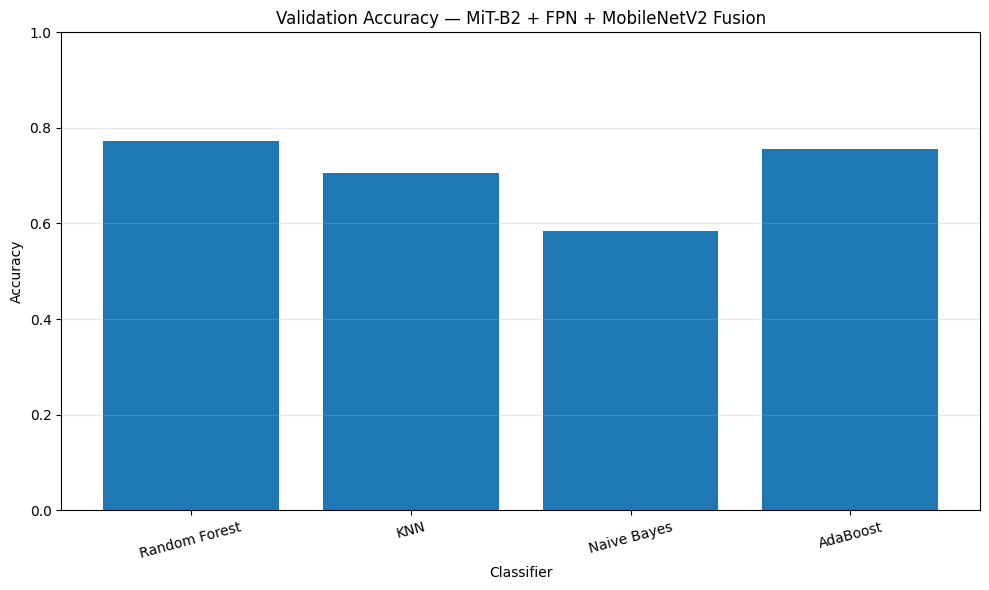

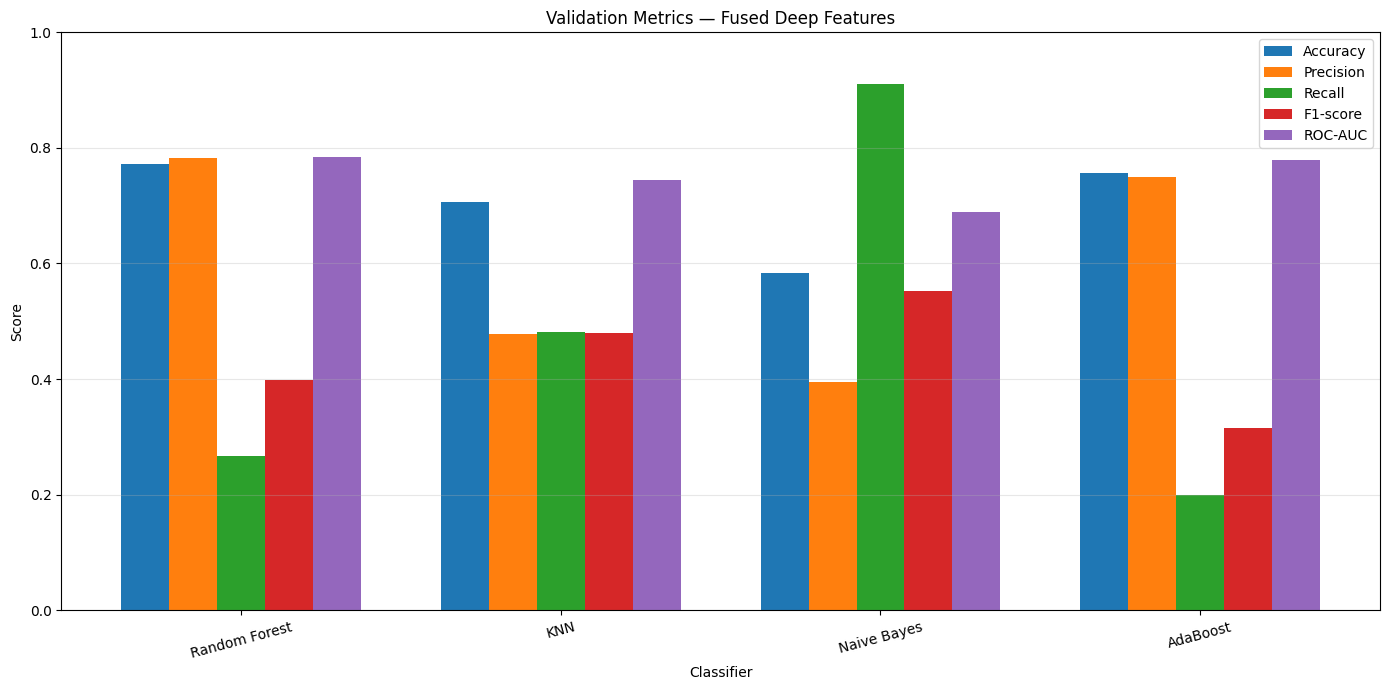

In [49]:
# ============================================================
# CELL 23 — VALIDATION COMPARISON
# ============================================================

validation_results = pd.DataFrame({

    "Classifier": [
        "Random Forest",
        "KNN",
        "Naive Bayes",
        "AdaBoost"
    ],

    "Accuracy": [
        rf_val_accuracy,
        knn_val_accuracy,
        nb_val_accuracy,
        adaboost_val_accuracy
    ],

    "Precision": [
        rf_val_precision,
        knn_val_precision,
        nb_val_precision,
        adaboost_val_precision
    ],

    "Recall": [
        rf_val_recall,
        knn_val_recall,
        nb_val_recall,
        adaboost_val_recall
    ],

    "F1-score": [
        rf_val_f1,
        knn_val_f1,
        nb_val_f1,
        adaboost_val_f1
    ],

    "ROC-AUC": [
        rf_val_auc,
        knn_val_auc,
        nb_val_auc,
        adaboost_val_auc
    ]
})


# ------------------------------------------------------------
# Display table
# ------------------------------------------------------------

print("=" * 80)
print("VALIDATION PERFORMANCE — FUSED FEATURES")
print("=" * 80)

display(
    validation_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


# ------------------------------------------------------------
# Bar chart — Validation Accuracy
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    validation_results["Classifier"],
    validation_results["Accuracy"]
)

plt.xlabel("Classifier")
plt.ylabel("Accuracy")
plt.title(
    "Validation Accuracy — MiT-B2 + FPN + MobileNetV2 Fusion"
)

plt.ylim(0, 1.0)
plt.xticks(rotation=15)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Bar chart — All Metrics
# ------------------------------------------------------------

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

x = np.arange(
    len(validation_results["Classifier"])
)

width = 0.15

plt.figure(figsize=(14, 7))

for i, metric in enumerate(metrics):

    plt.bar(
        x + (i - 2) * width,
        validation_results[metric],
        width=width,
        label=metric
    )

plt.xlabel("Classifier")
plt.ylabel("Score")
plt.title(
    "Validation Metrics — Fused Deep Features"
)

plt.xticks(
    x,
    validation_results["Classifier"],
    rotation=15
)

plt.ylim(0, 1.0)

plt.legend()
plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [50]:
# ============================================================
# CELL 24 — EXTRACT TEST FEATURES
# ============================================================

# ------------------------------------------------------------
# Create deterministic test feature loader
# ------------------------------------------------------------

feature_test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# 1. MiT-B2 + FPN TEST FEATURES
# ============================================================

mit_fpn_model.load_state_dict(
    best_mit_state
)

mit_fpn_model.eval()

mit_test_features, mit_test_labels = extract_mit_features(
    mit_fpn_model,
    feature_test_loader,
    device
)


# ============================================================
# 2. MobileNetV2 TEST FEATURES
# ============================================================

mobilenet_model.load_state_dict(
    best_mobilenet_state
)

mobilenet_model.eval()

mobilenet_test_features, mobilenet_test_labels = (
    extract_mobilenet_features(
        mobilenet_model,
        feature_test_loader,
        device
    )
)


# ============================================================
# 3. VERIFY LABEL ALIGNMENT
# ============================================================

test_labels_match = np.array_equal(
    mit_test_labels,
    mobilenet_test_labels
)

print("\n" + "=" * 60)
print("TEST FEATURE ALIGNMENT")
print("=" * 60)

print(
    "Test labels match:",
    test_labels_match
)


# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

assert test_labels_match, (
    "ERROR: MiT-B2 and MobileNetV2 test "
    "labels are not aligned."
)


# ============================================================
# 4. FUSE TEST FEATURES
# ============================================================

fused_test_features = np.concatenate(
    [
        mit_test_features,
        mobilenet_test_features
    ],
    axis=1
)

fused_test_labels = mit_test_labels.copy()


# ============================================================
# 5. APPLY THE EXISTING SCALER
# ============================================================
#
# IMPORTANT:
# We DO NOT fit a new scaler on the test set.
# The scaler was fitted only on training features in Cell 18.
# ------------------------------------------------------------

fused_test_features_scaled = feature_scaler.transform(
    fused_test_features
)


# ============================================================
# 6. VERIFY SHAPES
# ============================================================

print("\n" + "=" * 60)
print("TEST FEATURE EXTRACTION COMPLETE")
print("=" * 60)

print(
    "MiT-B2 + FPN test features :",
    mit_test_features.shape
)

print(
    "MobileNetV2 test features  :",
    mobilenet_test_features.shape
)

print(
    "Fused test features        :",
    fused_test_features.shape
)

print(
    "Scaled test features       :",
    fused_test_features_scaled.shape
)

print(
    "Test labels                :",
    fused_test_labels.shape
)

print("=" * 60)

Extracting MiT-B2 + FPN features:   0%|          | 0/46 [00:00<?, ?it/s]

Extracting MobileNetV2 features:   0%|          | 0/46 [00:00<?, ?it/s]


TEST FEATURE ALIGNMENT
Test labels match: True

TEST FEATURE EXTRACTION COMPLETE
MiT-B2 + FPN test features : (1468, 256)
MobileNetV2 test features  : (1468, 1280)
Fused test features        : (1468, 1536)
Scaled test features       : (1468, 1536)
Test labels                : (1468,)


In [51]:
# ============================================================
# CELL 25 — RANDOM FOREST FINAL TEST EVALUATION
# ============================================================

# ------------------------------------------------------------
# Test predictions
# ------------------------------------------------------------

rf_test_predictions = rf_model.predict(
    fused_test_features_scaled
)

rf_test_probabilities = rf_model.predict_proba(
    fused_test_features_scaled
)[:, 1]


# ------------------------------------------------------------
# Calculate metrics
# ------------------------------------------------------------

rf_test_accuracy = accuracy_score(
    fused_test_labels,
    rf_test_predictions
)

rf_test_precision = precision_score(
    fused_test_labels,
    rf_test_predictions,
    zero_division=0
)

rf_test_recall = recall_score(
    fused_test_labels,
    rf_test_predictions,
    zero_division=0
)

rf_test_f1 = f1_score(
    fused_test_labels,
    rf_test_predictions,
    zero_division=0
)

rf_test_auc = roc_auc_score(
    fused_test_labels,
    rf_test_probabilities
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("=" * 60)
print("RANDOM FOREST — FINAL TEST RESULTS")
print("=" * 60)

print(f"Test Accuracy : {rf_test_accuracy:.4f}")
print(f"Test Precision: {rf_test_precision:.4f}")
print(f"Test Recall   : {rf_test_recall:.4f}")
print(f"Test F1-score : {rf_test_f1:.4f}")
print(f"Test ROC-AUC  : {rf_test_auc:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        fused_test_labels,
        rf_test_predictions,
        target_names=class_names,
        zero_division=0
    )
)

RANDOM FOREST — FINAL TEST RESULTS
Test Accuracy : 0.8631
Test Precision: 0.9151
Test Recall   : 0.5697
Test F1-score : 0.7022
Test ROC-AUC  : 0.9461

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal       0.85      0.98      0.91      1052
  Appears normal       0.92      0.57      0.70       416

        accuracy                           0.86      1468
       macro avg       0.88      0.77      0.81      1468
    weighted avg       0.87      0.86      0.85      1468



In [52]:
# ============================================================
# CELL 26 — FIXED DETERMINISTIC FEATURE EXTRACTION
# ============================================================

# ------------------------------------------------------------
# Find the trained MiT-B2 model automatically
# ------------------------------------------------------------

mit_model = None

# Check common variable names first
for name in ["mit_model", "model_mit", "mit_fpn_model"]:
    if name in globals() and isinstance(globals()[name], nn.Module):
        mit_model = globals()[name]
        print(f"Using MiT model variable: {name}")
        break

# If not found, search by model class
if mit_model is None:
    for name, obj in globals().items():
        if isinstance(obj, MiTB2_FPN_Classifier):
            mit_model = obj
            print(f"Found MiT model automatically: {name}")
            break

if mit_model is None:
    raise RuntimeError(
        "MiT-B2 model was not found. Please rerun the MiT-B2 model definition cell."
    )


# ------------------------------------------------------------
# Load best MiT weights
# ------------------------------------------------------------

mit_model.load_state_dict(best_mit_state)
mit_model.to(device)
mit_model.eval()


# ------------------------------------------------------------
# Deterministic feature dataset
# ------------------------------------------------------------

feature_train_dataset = TransformSubset(
    full_train_dataset,
    train_indices,
    transform=eval_transform
)

feature_train_loader = DataLoader(
    feature_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# MiT-B2 FEATURES
# ============================================================

print("Extracting deterministic MiT-B2 train features...")

mit_train_features, mit_train_labels = extract_mit_features(
    mit_model,
    feature_train_loader,
    device
)


# ============================================================
# MOBILENETV2 FEATURES
# ============================================================

mobilenet_model.load_state_dict(best_mobilenet_state)
mobilenet_model.to(device)
mobilenet_model.eval()

print("Extracting deterministic MobileNetV2 train features...")

mobilenet_train_features, mobilenet_train_labels = extract_mobilenet_features(
    mobilenet_model,
    feature_train_loader,
    device
)


# ============================================================
# VERIFY LABEL ALIGNMENT
# ============================================================

print("\nLabel alignment check:")

print(
    "MiT == MobileNet:",
    np.array_equal(
        mit_train_labels,
        mobilenet_train_labels
    )
)

print(
    "MiT == Original:",
    np.array_equal(
        mit_train_labels,
        train_labels
    )
)

assert np.array_equal(
    mit_train_labels,
    mobilenet_train_labels
)

assert np.array_equal(
    mit_train_labels,
    train_labels
)


# ============================================================
# FUSE FEATURES
# ============================================================

fused_train_features = np.concatenate(
    [
        mit_train_features,
        mobilenet_train_features
    ],
    axis=1
)

fused_train_labels = mit_train_labels.copy()


# ============================================================
# PRINT RESULTS
# ============================================================

print("\nFeature shapes:")
print("MiT-B2       :", mit_train_features.shape)
print("MobileNetV2  :", mobilenet_train_features.shape)
print("Fused        :", fused_train_features.shape)
print("Labels       :", fused_train_labels.shape)

print("\nDeterministic feature extraction completed successfully.")

Using MiT model variable: model_mit
Extracting deterministic MiT-B2 train features...


Extracting MiT-B2 + FPN features:   0%|          | 0/85 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e421c447420>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e421c447420>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Extracting deterministic MobileNetV2 train features...


Extracting MobileNetV2 features:   0%|          | 0/85 [00:00<?, ?it/s]


Label alignment check:
MiT == MobileNet: True
MiT == Original: True

Feature shapes:
MiT-B2       : (2720, 256)
MobileNetV2  : (2720, 1280)
Fused        : (2720, 1536)
Labels       : (2720,)

Deterministic feature extraction completed successfully.


In [53]:
# ============================================================
# CELL 27 — SCALE FEATURES + TRAIN ALL CLASSIFIERS
# ============================================================

# ------------------------------------------------------------
# 1. Standardize fused features
# ------------------------------------------------------------

feature_scaler = StandardScaler()

# Fit ONLY on training features
fused_train_features_scaled = feature_scaler.fit_transform(
    fused_train_features
)

# Transform validation and test using the SAME scaler
fused_val_features_scaled = feature_scaler.transform(
    fused_val_features
)

fused_test_features_scaled = feature_scaler.transform(
    fused_test_features
)

print("Scaled feature shapes:")
print("Train:", fused_train_features_scaled.shape)
print("Val  :", fused_val_features_scaled.shape)
print("Test :", fused_test_features_scaled.shape)


# ============================================================
# 2. RANDOM FOREST
# ============================================================

print("\nTraining Random Forest...")

rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("Random Forest trained.")


# ============================================================
# 3. KNN
# ============================================================

print("\nTraining KNN...")

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="euclidean",
    n_jobs=-1
)

knn_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("KNN trained.")


# ============================================================
# 4. GAUSSIAN NAIVE BAYES
# ============================================================

print("\nTraining Gaussian Naive Bayes...")

nb_model = GaussianNB()

nb_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("Gaussian Naive Bayes trained.")


# ============================================================
# 5. ADABOOST
# ============================================================

print("\nTraining AdaBoost...")

adaboost_model = AdaBoostClassifier(
    n_estimators=300,
    learning_rate=0.05,
    random_state=SEED
)

adaboost_model.fit(
    fused_train_features_scaled,
    fused_train_labels
)

print("AdaBoost trained.")


# ============================================================
# FINAL CHECK
# ============================================================

print("\n" + "=" * 60)
print("ALL CLASSIFIERS TRAINED SUCCESSFULLY")
print("=" * 60)

print("Random Forest       : READY")
print("KNN                 : READY")
print("Gaussian Naive Bayes: READY")
print("AdaBoost            : READY")

Scaled feature shapes:
Train: (2720, 1536)
Val  : (480, 1536)
Test : (1468, 1536)

Training Random Forest...
Random Forest trained.

Training KNN...
KNN trained.

Training Gaussian Naive Bayes...
Gaussian Naive Bayes trained.

Training AdaBoost...
AdaBoost trained.

ALL CLASSIFIERS TRAINED SUCCESSFULLY
Random Forest       : READY
KNN                 : READY
Gaussian Naive Bayes: READY
AdaBoost            : READY



Random Forest — FINAL TEST RESULTS
Test Accuracy : 0.8685
Test Precision: 0.8756
Test Recall   : 0.8685
Test F1-score : 0.8582
Test ROC-AUC  : 0.9563

Confusion Matrix:
[[1032   20]
 [ 173  243]]

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.8564    0.9810    0.9145      1052
  Appears normal     0.9240    0.5841    0.7158       416

        accuracy                         0.8685      1468
       macro avg     0.8902    0.7826    0.8151      1468
    weighted avg     0.8756    0.8685    0.8582      1468



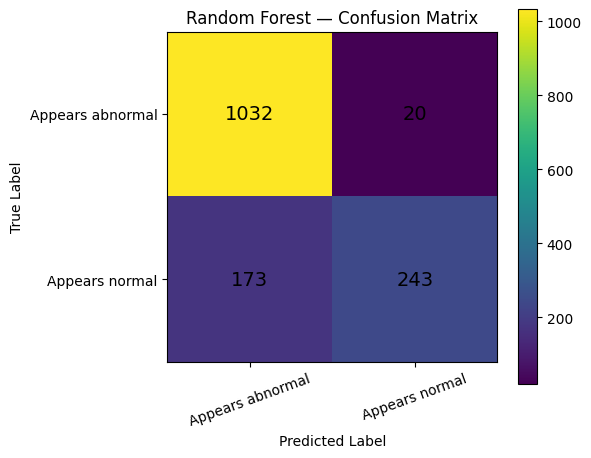


KNN — FINAL TEST RESULTS
Test Accuracy : 0.8896
Test Precision: 0.8924
Test Recall   : 0.8896
Test F1-score : 0.8839
Test ROC-AUC  : 0.9101

Confusion Matrix:
[[1027   25]
 [ 137  279]]

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.8823    0.9762    0.9269      1052
  Appears normal     0.9178    0.6707    0.7750       416

        accuracy                         0.8896      1468
       macro avg     0.9000    0.8235    0.8509      1468
    weighted avg     0.8924    0.8896    0.8839      1468



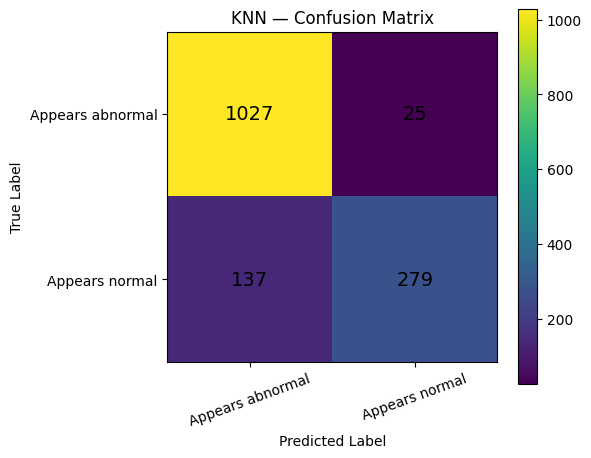


Gaussian Naive Bayes — FINAL TEST RESULTS
Test Accuracy : 0.9285
Test Precision: 0.9293
Test Recall   : 0.9285
Test F1-score : 0.9288
Test ROC-AUC  : 0.9204

Confusion Matrix:
[[993  59]
 [ 46 370]]

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.9557    0.9439    0.9498      1052
  Appears normal     0.8625    0.8894    0.8757       416

        accuracy                         0.9285      1468
       macro avg     0.9091    0.9167    0.9128      1468
    weighted avg     0.9293    0.9285    0.9288      1468



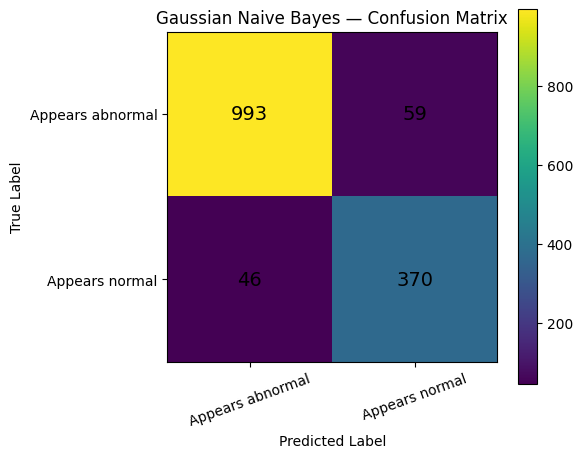


AdaBoost — FINAL TEST RESULTS
Test Accuracy : 0.8631
Test Precision: 0.8698
Test Recall   : 0.8631
Test F1-score : 0.8519
Test ROC-AUC  : 0.9340

Confusion Matrix:
[[1030   22]
 [ 179  237]]

Classification Report:
                  precision    recall  f1-score   support

Appears abnormal     0.8519    0.9791    0.9111      1052
  Appears normal     0.9151    0.5697    0.7022       416

        accuracy                         0.8631      1468
       macro avg     0.8835    0.7744    0.8067      1468
    weighted avg     0.8698    0.8631    0.8519      1468



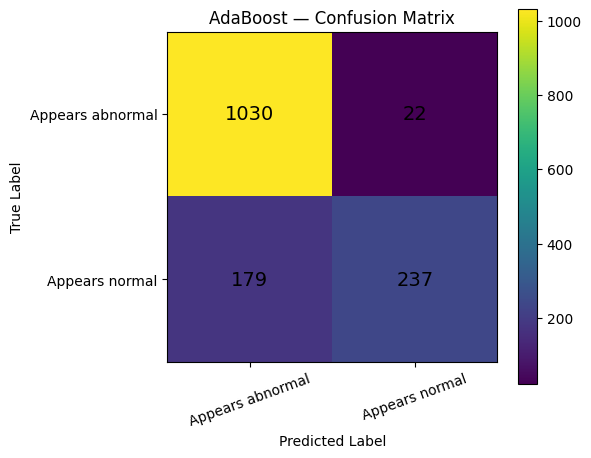



FINAL TEST COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.8685,0.8756,0.8685,0.8582,0.9563
1,KNN,0.8896,0.8924,0.8896,0.8839,0.9101
2,Gaussian Naive Bayes,0.9285,0.9293,0.9285,0.9288,0.9204
3,AdaBoost,0.8631,0.8698,0.8631,0.8519,0.9340


In [54]:
# ============================================================
# CELL 28 — FINAL TEST EVALUATION + CONFUSION MATRICES
# ============================================================

def evaluate_classifier(model, model_name):

    predictions = model.predict(fused_test_features_scaled)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(
            fused_test_features_scaled
        )[:, 1]
    else:
        probabilities = None

    accuracy = accuracy_score(
        test_labels,
        predictions
    )

    precision = precision_score(
        test_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        test_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        test_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    if probabilities is not None:
        roc_auc = roc_auc_score(
            test_labels,
            probabilities
        )
    else:
        roc_auc = np.nan

    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        test_labels,
        predictions
    )

    print("\n" + "=" * 65)
    print(f"{model_name} — FINAL TEST RESULTS")
    print("=" * 65)

    print(f"Test Accuracy : {accuracy:.4f}")
    print(f"Test Precision: {precision:.4f}")
    print(f"Test Recall   : {recall:.4f}")
    print(f"Test F1-score : {f1:.4f}")
    print(f"Test ROC-AUC  : {roc_auc:.4f}")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(
        classification_report(
            test_labels,
            predictions,
            target_names=test_dataset.classes,
            digits=4,
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # Plot Confusion Matrix
    # --------------------------------------------------------

    plt.figure(figsize=(6, 5))

    plt.imshow(cm)

    plt.title(f"{model_name} — Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    plt.xticks(
        [0, 1],
        test_dataset.classes,
        rotation=20
    )

    plt.yticks(
        [0, 1],
        test_dataset.classes
    )

    # Add numbers inside matrix
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center",
                fontsize=14
            )

    plt.colorbar()
    plt.tight_layout()
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": roc_auc,
        "Confusion Matrix": cm
    }


# ============================================================
# EVALUATE ALL FOUR CLASSIFIERS
# ============================================================

rf_results = evaluate_classifier(
    rf_model,
    "Random Forest"
)

knn_results = evaluate_classifier(
    knn_model,
    "KNN"
)

nb_results = evaluate_classifier(
    nb_model,
    "Gaussian Naive Bayes"
)

adaboost_results = evaluate_classifier(
    adaboost_model,
    "AdaBoost"
)


# ============================================================
# FINAL COMPARISON TABLE
# ============================================================

final_results = pd.DataFrame([
    rf_results,
    knn_results,
    nb_results,
    adaboost_results
])

# Remove confusion matrix from displayed comparison table
comparison_table = final_results[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ]
]

print("\n")
print("=" * 80)
print("FINAL TEST COMPARISON")
print("=" * 80)

display(
    comparison_table.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)